# Global land cover from coordinates

Train a [Wrap encoder](https://github.com/MarcCoru/locationencoder/blob/main/locationencoder/pe/wrap.py) and MLP on the [CGLC-MODIS-LCZ map](https://zenodo.org/records/7670653), then visualize and classify the bottleneck embeddings.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neuralearthfields/neuralearthfields-starter/blob/main/starter.ipynb)

## Setup

Locally, run `uv sync` and `uv run jupyter lab`. In Colab, select a GPU runtime and run the installation cell below; restart if prompted.

In [1]:
import os
import subprocess
import sys
import tomllib
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/neuralearthfields-starter")
    if not repo.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/neuralearthfields/neuralearthfields-starter.git",
                str(repo),
            ],
            check=True,
        )
    os.chdir(repo)
    sys.path.insert(0, str(repo))
    dependencies = tomllib.loads(Path("pyproject.toml").read_text())["project"][
        "dependencies"
    ]
    subprocess.run([sys.executable, "-m", "pip", "install", *dependencies], check=True)

## Configuration

Edit `Config` below. The default architecture is `Wrap (4) → 256 → 128 → 256 → 31`; `hidden_dim` sets the embedding size.

In [2]:
from pathlib import Path

import lightning as L
import torch
from lightning.pytorch.loggers import CSVLogger
from torch import nn
from torch.utils.data import DataLoader
from torchmetrics import MetricCollection
from torchmetrics.classification import (
    MulticlassAccuracy,
    MulticlassF1Score,
    MulticlassJaccardIndex,
)

from dataset import LandCoverDataset
from plot import (
    pca_rgb,
    plot_comparison,
    plot_land_cover,
    plot_metrics,
    preview_grid,
    read_palette,
)


class Config:
    source = Path("data/CGLC-MODIS-LCZ-100m.cog.tif")
    output = Path("outputs")
    input_dim = 256
    hidden_dim = 128
    output_dim = 256
    batch_size = 4096
    train_samples = 2**20
    train_steps = 5000
    probe_steps = 1000
    test_batches = 16
    eval_every = 250
    learning_rate = 1e-3
    nearby_fraction = 0.5
    radius_pixels = 5
    preview_height = 768
    seed = 0


cfg = Config()
cfg.output.mkdir(parents=True, exist_ok=True)
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(cfg.seed)
torch.set_num_threads(4)
torch.set_float32_matmul_precision("high")
print(device)

/Users/isaaccorley/github/neuralearthfields-starter/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mps


## Dataset

`LandCoverDataset` in [dataset.py](dataset.py) downloads the COG and samples a fixed pool of land/lake coordinates. Nearby samples can repeat pixels, so a pixel hash keeps training and validation disjoint. Tiles contribute equal sample counts; sampling is not uniform over all land pixels.

In [3]:
train_data = LandCoverDataset(
    cfg.source,
    cfg.train_samples,
    nearby_fraction=cfg.nearby_fraction,
    radius_pixels=cfg.radius_pixels,
    seed=cfg.seed,
)
validation_data = LandCoverDataset(
    cfg.source,
    cfg.test_batches * cfg.batch_size,
    split="validation",
    seed=cfg.seed + 1,
)
train_loader = DataLoader(train_data, batch_size=cfg.batch_size, shuffle=True)
validation_loader = DataLoader(validation_data, batch_size=cfg.batch_size)
class_codes = train_data.class_codes
num_classes = len(class_codes)
print(
    f"{len(train_data):,} training pixels; {len(validation_data):,} validation pixels"
)

1,048,576 training pixels; 65,536 validation pixels


## Land cover

Include land and lakes (21); exclude ocean (17) and invalid labels.

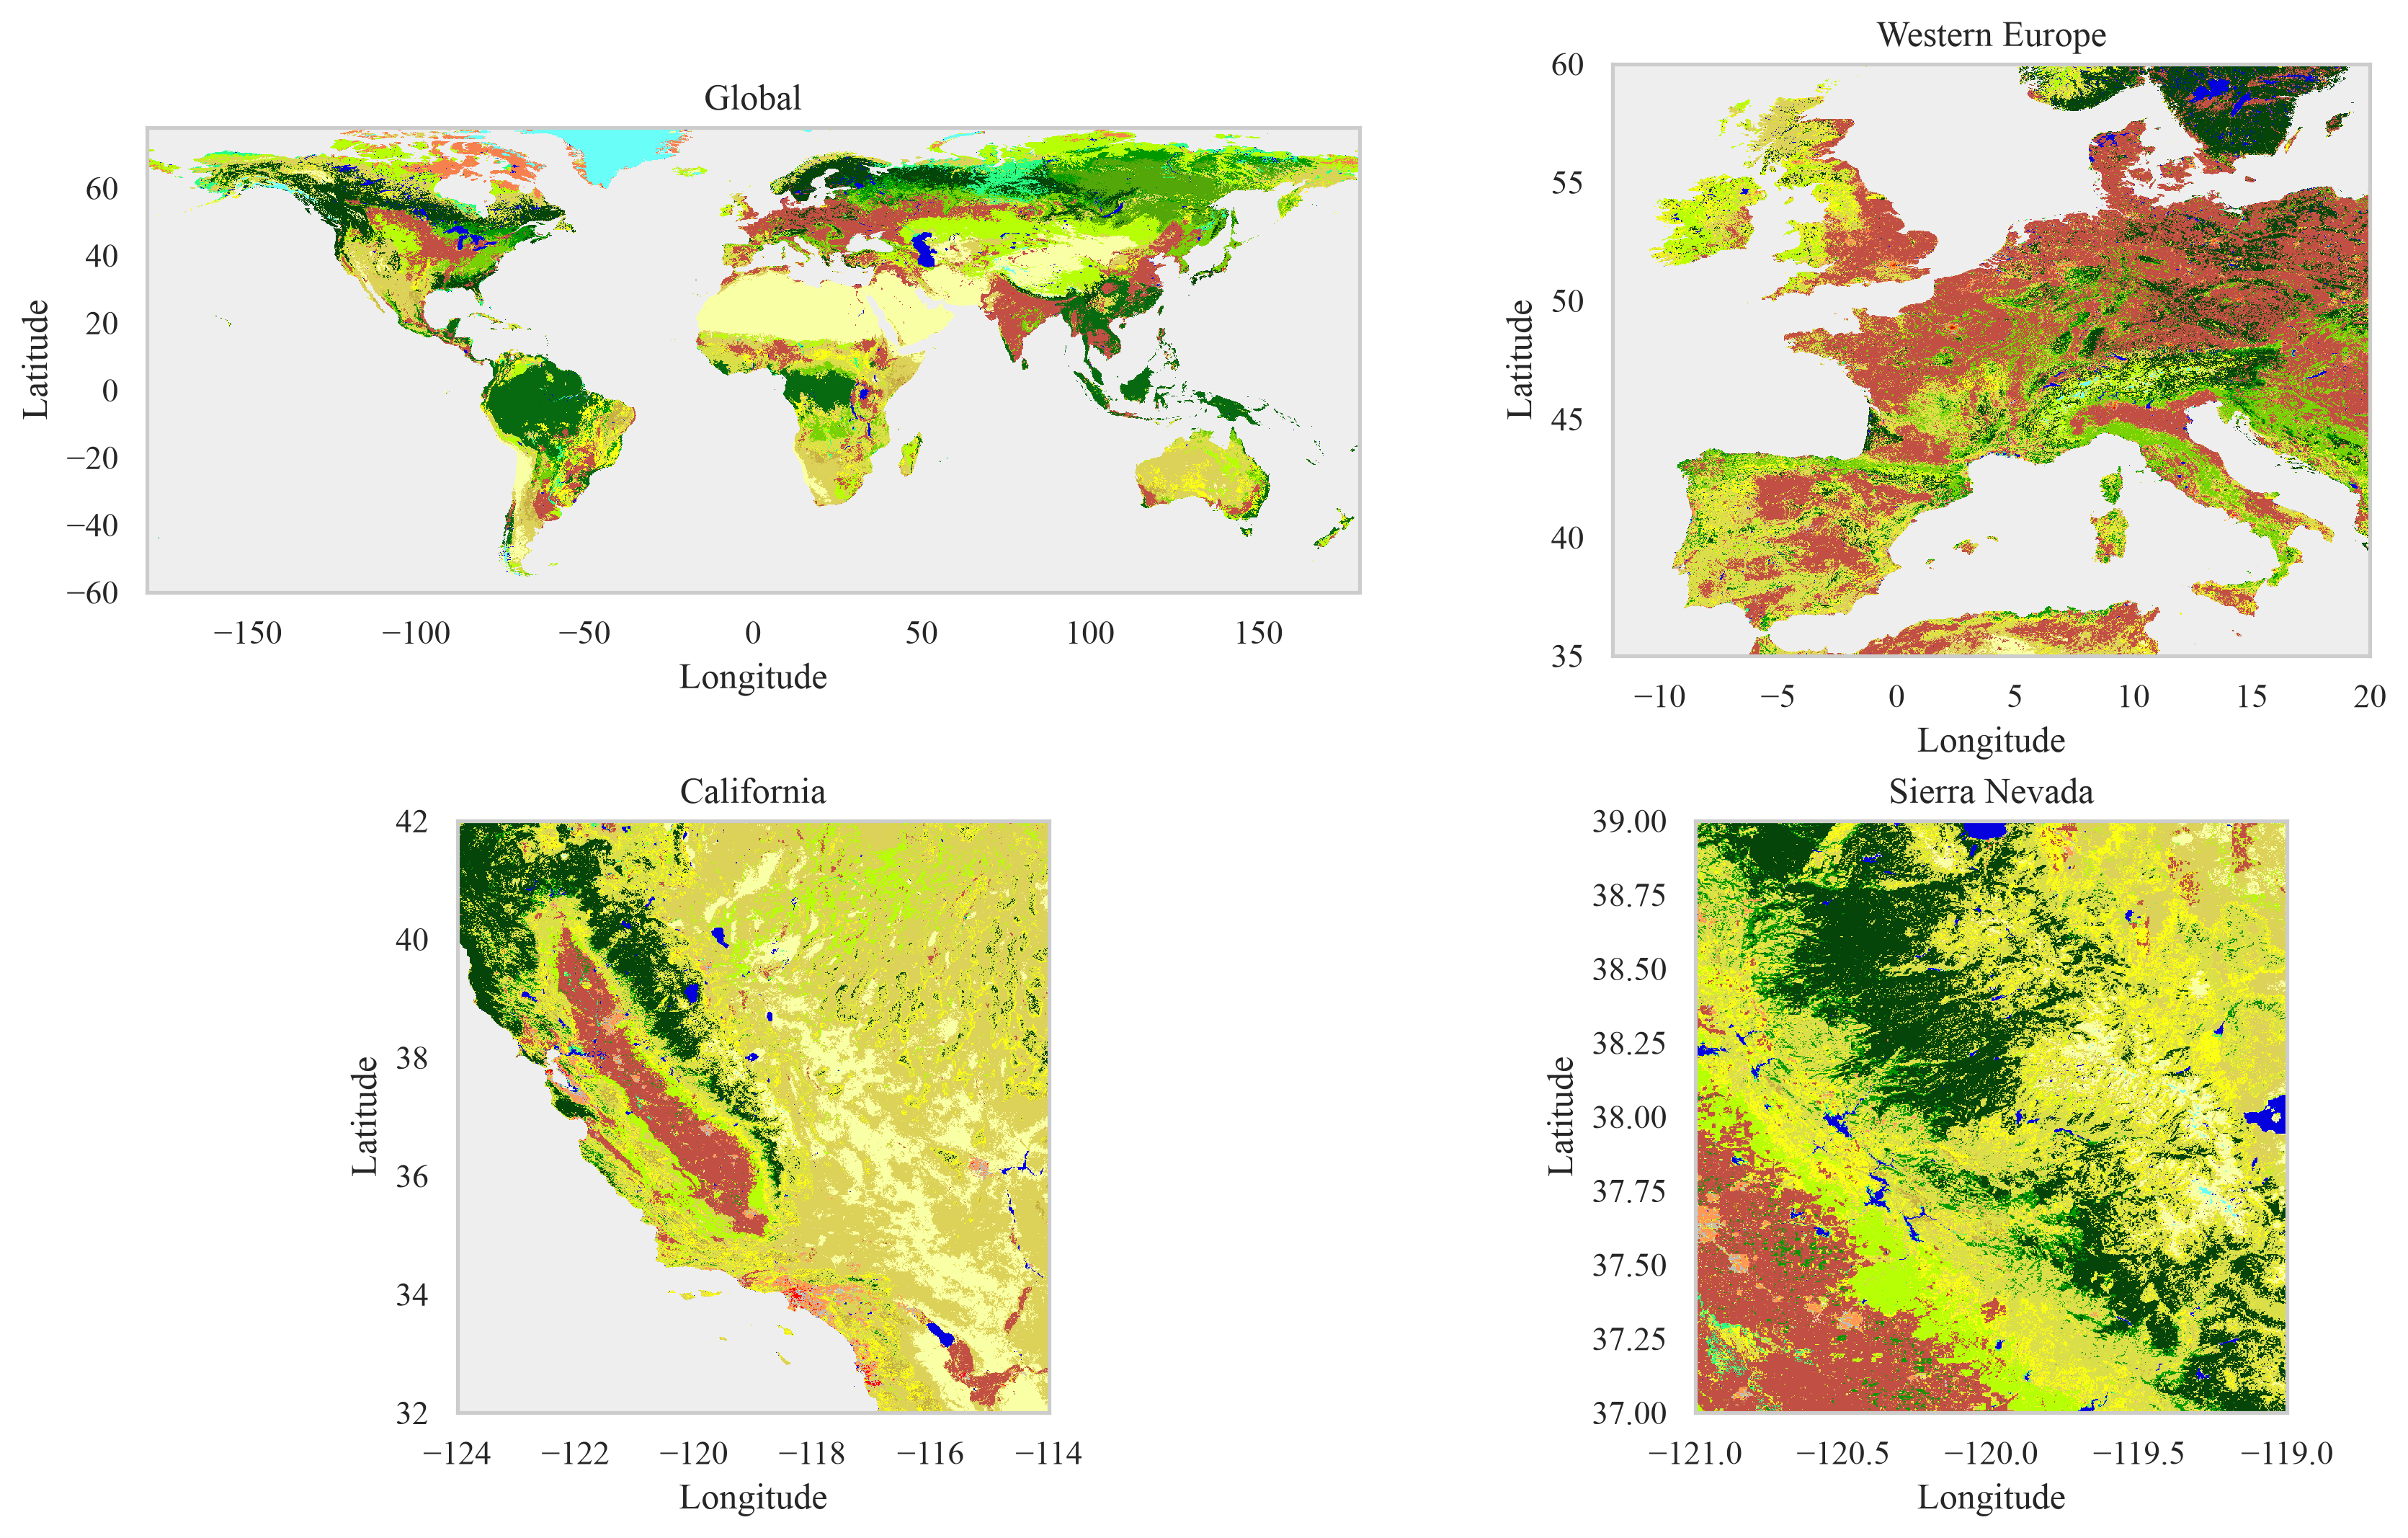

In [4]:
colors = read_palette(cfg.source, class_codes)
plot_land_cover(cfg.source, colors, cfg.output / "land_cover.png")

## Wrap + MLP

Wrap encodes longitude and latitude in degrees as sine/cosine features without modifying the input. `model[0]` returns the middle bottleneck.

In [5]:
class Wrap(nn.Module):
    def forward(self, coords):
        # Each lon/lat pair becomes [cos(lon), sin(lon), cos(lat), sin(lat)].
        radians = coords * (torch.pi / 180)
        return torch.stack((radians.cos(), radians.sin()), dim=-1).flatten(1)


# The bottleneck is the embedding exported to ONNX.
encoder = nn.Sequential(
    Wrap(),
    nn.Linear(4, cfg.input_dim),
    nn.ReLU(inplace=True),
    nn.Linear(cfg.input_dim, cfg.hidden_dim),
    nn.ReLU(inplace=True),
)
# The decoder and classifier provide land-cover supervision during training.
decoder = nn.Sequential(
    nn.Linear(cfg.hidden_dim, cfg.output_dim), nn.ReLU(inplace=True)
)
model = nn.Sequential(encoder, decoder, nn.Linear(cfg.output_dim, num_classes)).to(
    device
)
criterion = nn.CrossEntropyLoss()
print(model)

Sequential(
  (0): Sequential(
    (0): Wrap()
    (1): Linear(in_features=4, out_features=256, bias=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU(inplace=True)
  )
  (1): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): ReLU(inplace=True)
  )
  (2): Linear(in_features=256, out_features=31, bias=True)
)


## Training

Train with Lightning and log TorchMetrics results. Validation uses a fixed pixel split and measures interpolation within the map. Curves below are from one run.

GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/isaaccorley/github/neuralearthfields-starter/.venv/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/isaaccorley/github/neuralearthfields-starter/.venv/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=17` in the `DataLoader` to improve performance.
/Users/isaaccorley/github/neuralearthfields-starter/.venv/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=17` in the `DataLoader` to improve performance.


`Trainer.fit` stopped: `max_steps=5000` reached.


{'cross_entropy': 1.4098371267318726, 'accuracy': 0.51434326171875, 'macro_f1': 0.2739182114601135, 'miou': 0.19966347515583038}


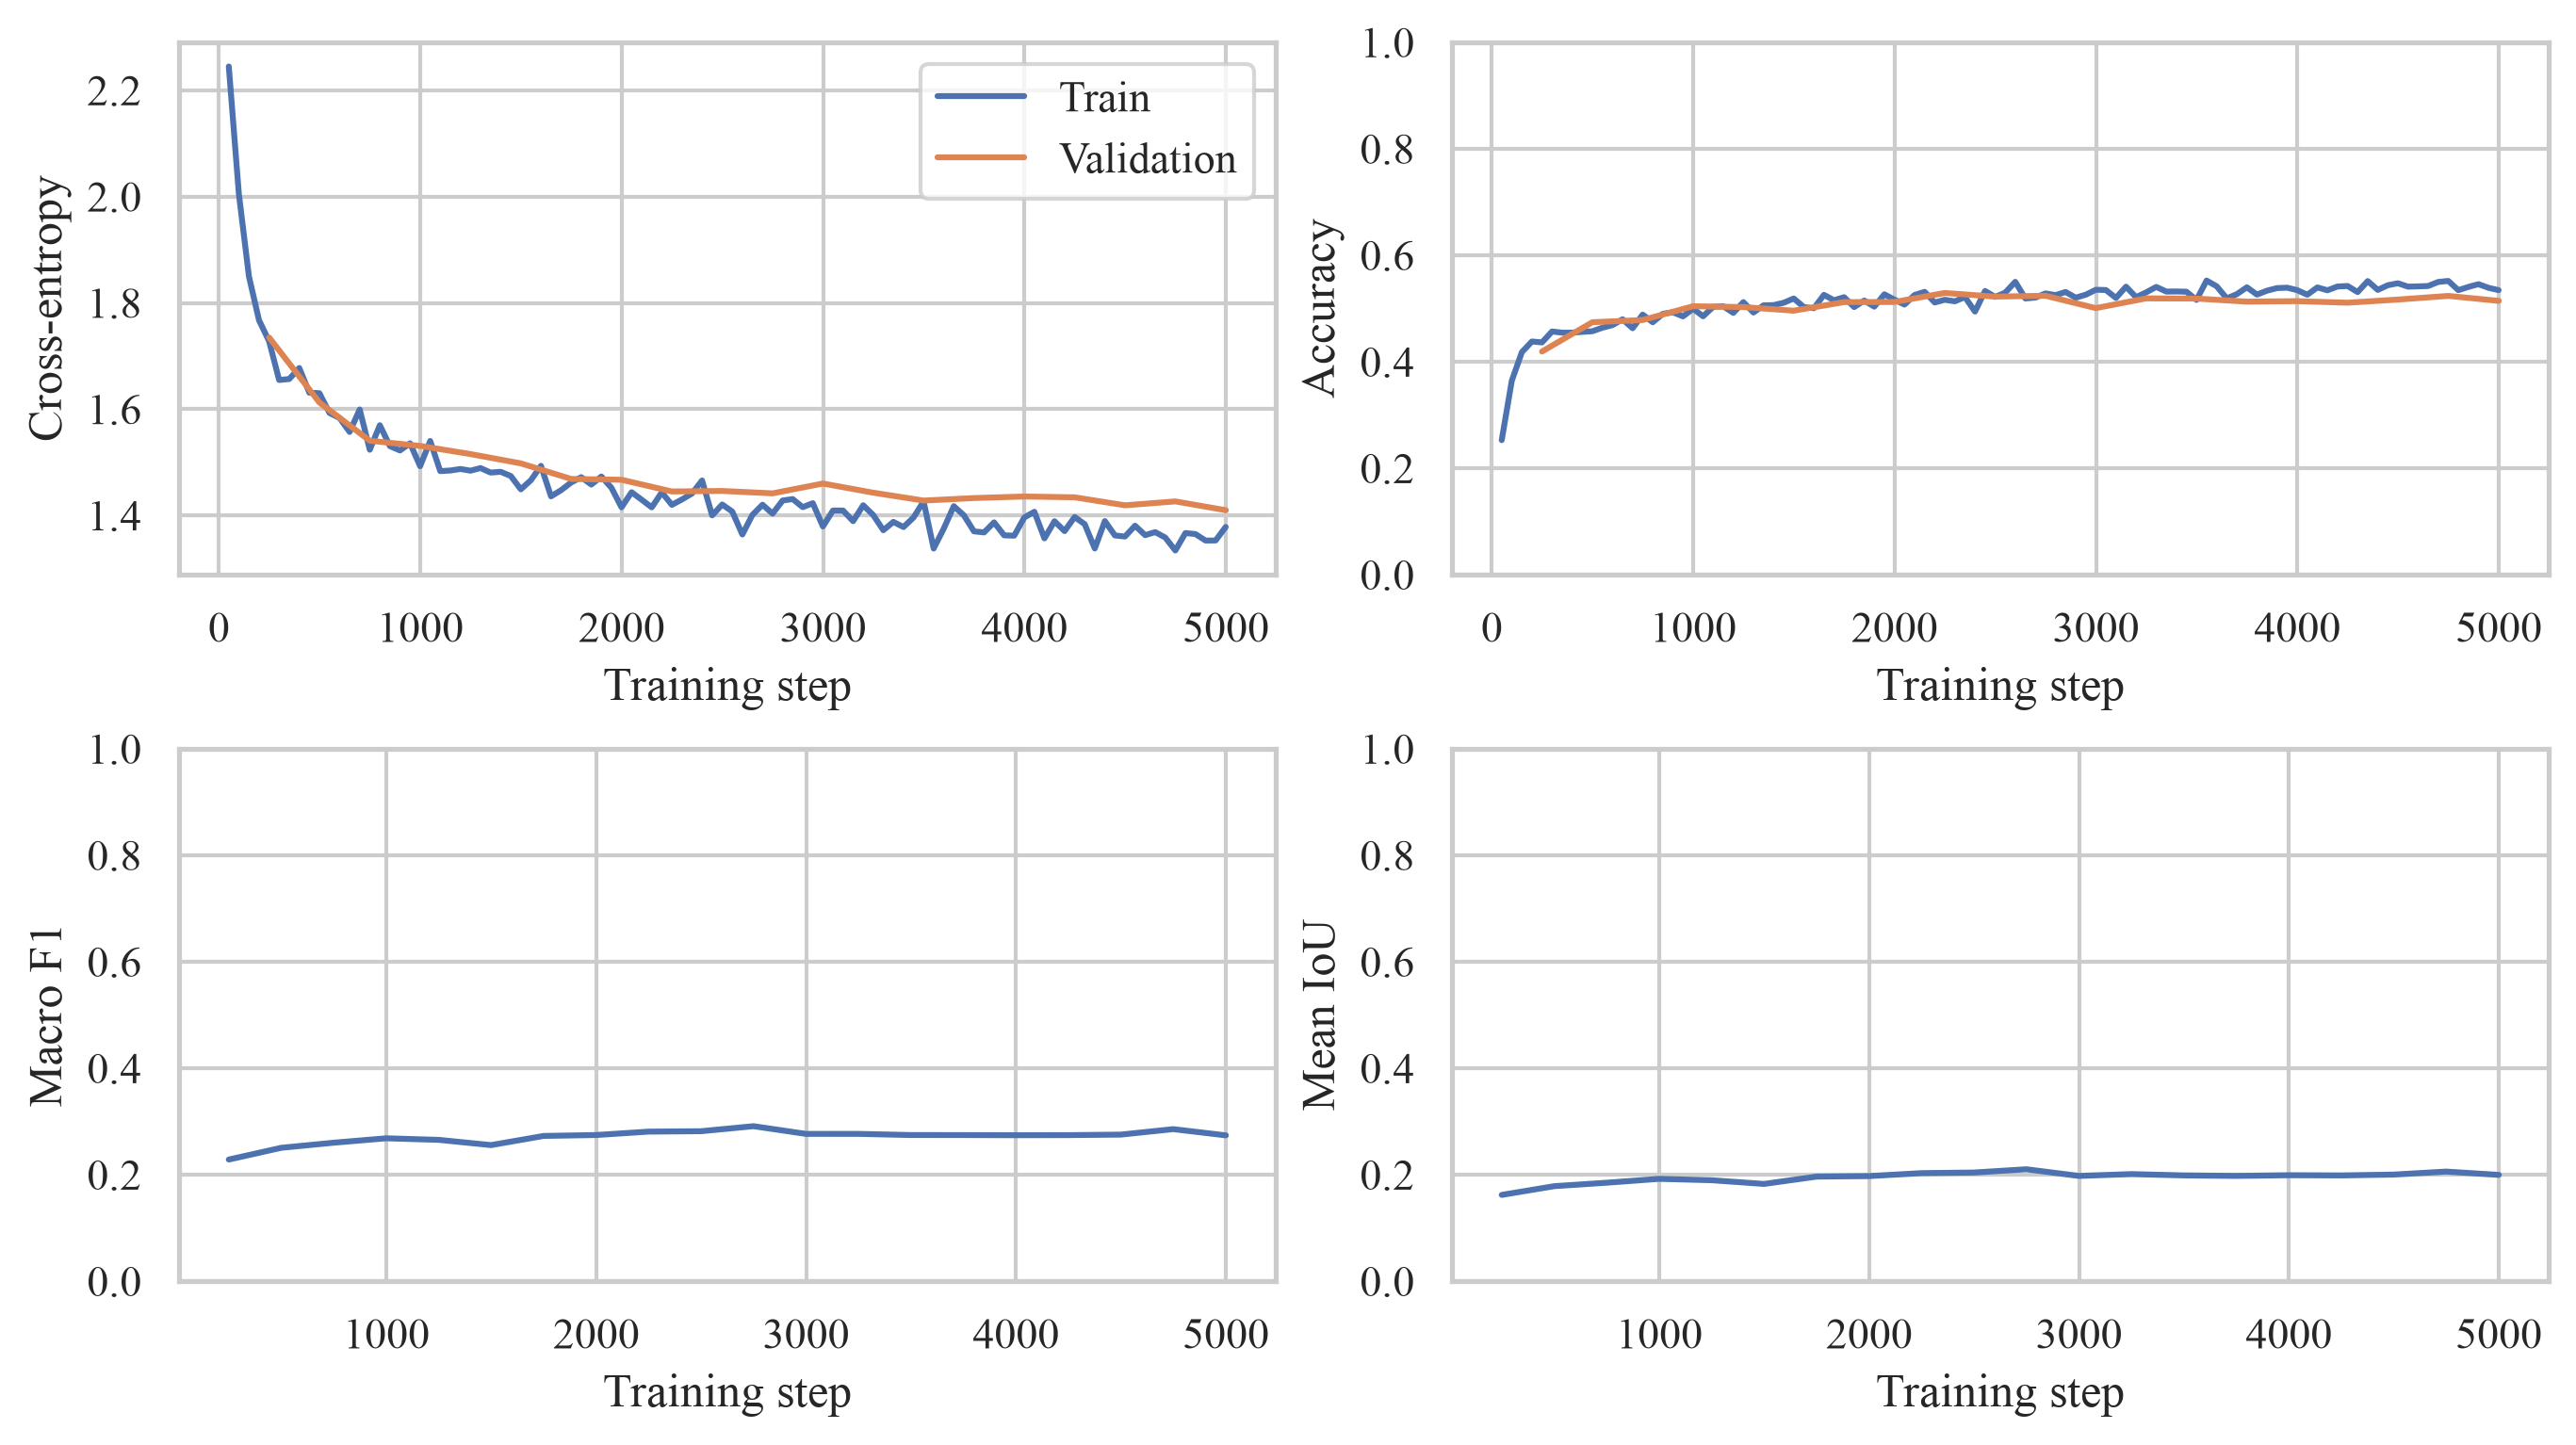

In [6]:
class LandCoverTask(L.LightningModule):
    def __init__(self, network):
        super().__init__()
        self.network = network
        self.train_accuracy = MulticlassAccuracy(
            num_classes=num_classes, average="micro"
        )
        self.validation_metrics = MetricCollection(
            {
                "accuracy": MulticlassAccuracy(
                    num_classes=num_classes, average="micro"
                ),
                "macro_f1": MulticlassF1Score(num_classes=num_classes, average="macro"),
                "miou": MulticlassJaccardIndex(
                    num_classes=num_classes, average="macro"
                ),
            }
        )

    def training_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords)
        loss = criterion(logits, target)
        self.train_accuracy(logits, target)
        self.log("train_loss", loss)
        self.log("train_accuracy", self.train_accuracy, on_step=True, on_epoch=False)
        return loss

    def validation_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords.clone())
        self.log("cross_entropy", criterion(logits, target), batch_size=len(target))
        self.validation_metrics.update(logits, target)
        self.log_dict(self.validation_metrics, on_step=False, on_epoch=True)

    def configure_optimizers(self):
        return torch.optim.Adam(
            (p for p in self.parameters() if p.requires_grad), lr=cfg.learning_rate
        )


def fit(network, steps, name):
    logger = CSVLogger(cfg.output, name=name)
    trainer = L.Trainer(
        accelerator=device.type,
        devices=1,
        max_steps=steps,
        val_check_interval=min(cfg.eval_every, steps),
        check_val_every_n_epoch=None,
        log_every_n_steps=min(50, steps),
        num_sanity_val_steps=0,
        enable_checkpointing=False,
        enable_progress_bar=False,
        enable_model_summary=False,
        logger=logger,
    )
    task = LandCoverTask(network)
    trainer.fit(task, train_loader, validation_loader)
    print(trainer.validate(task, validation_loader, verbose=False)[0])
    network.to(device).eval()
    return Path(logger.log_dir) / "metrics.csv"


history = fit(model, cfg.train_steps, "wrap_mlp")
plot_metrics(history, cfg.output / "wrap_mlp_metrics.png")

## Linear probe

Freeze the bottleneck and fit a fresh linear classifier directly on its embeddings.

GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/isaaccorley/github/neuralearthfields-starter/.venv/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:538: Found 6 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


`Trainer.fit` stopped: `max_steps=1000` reached.


{'cross_entropy': 1.8145501613616943, 'accuracy': 0.416351318359375, 'macro_f1': 0.204874649643898, 'miou': 0.14499688148498535}


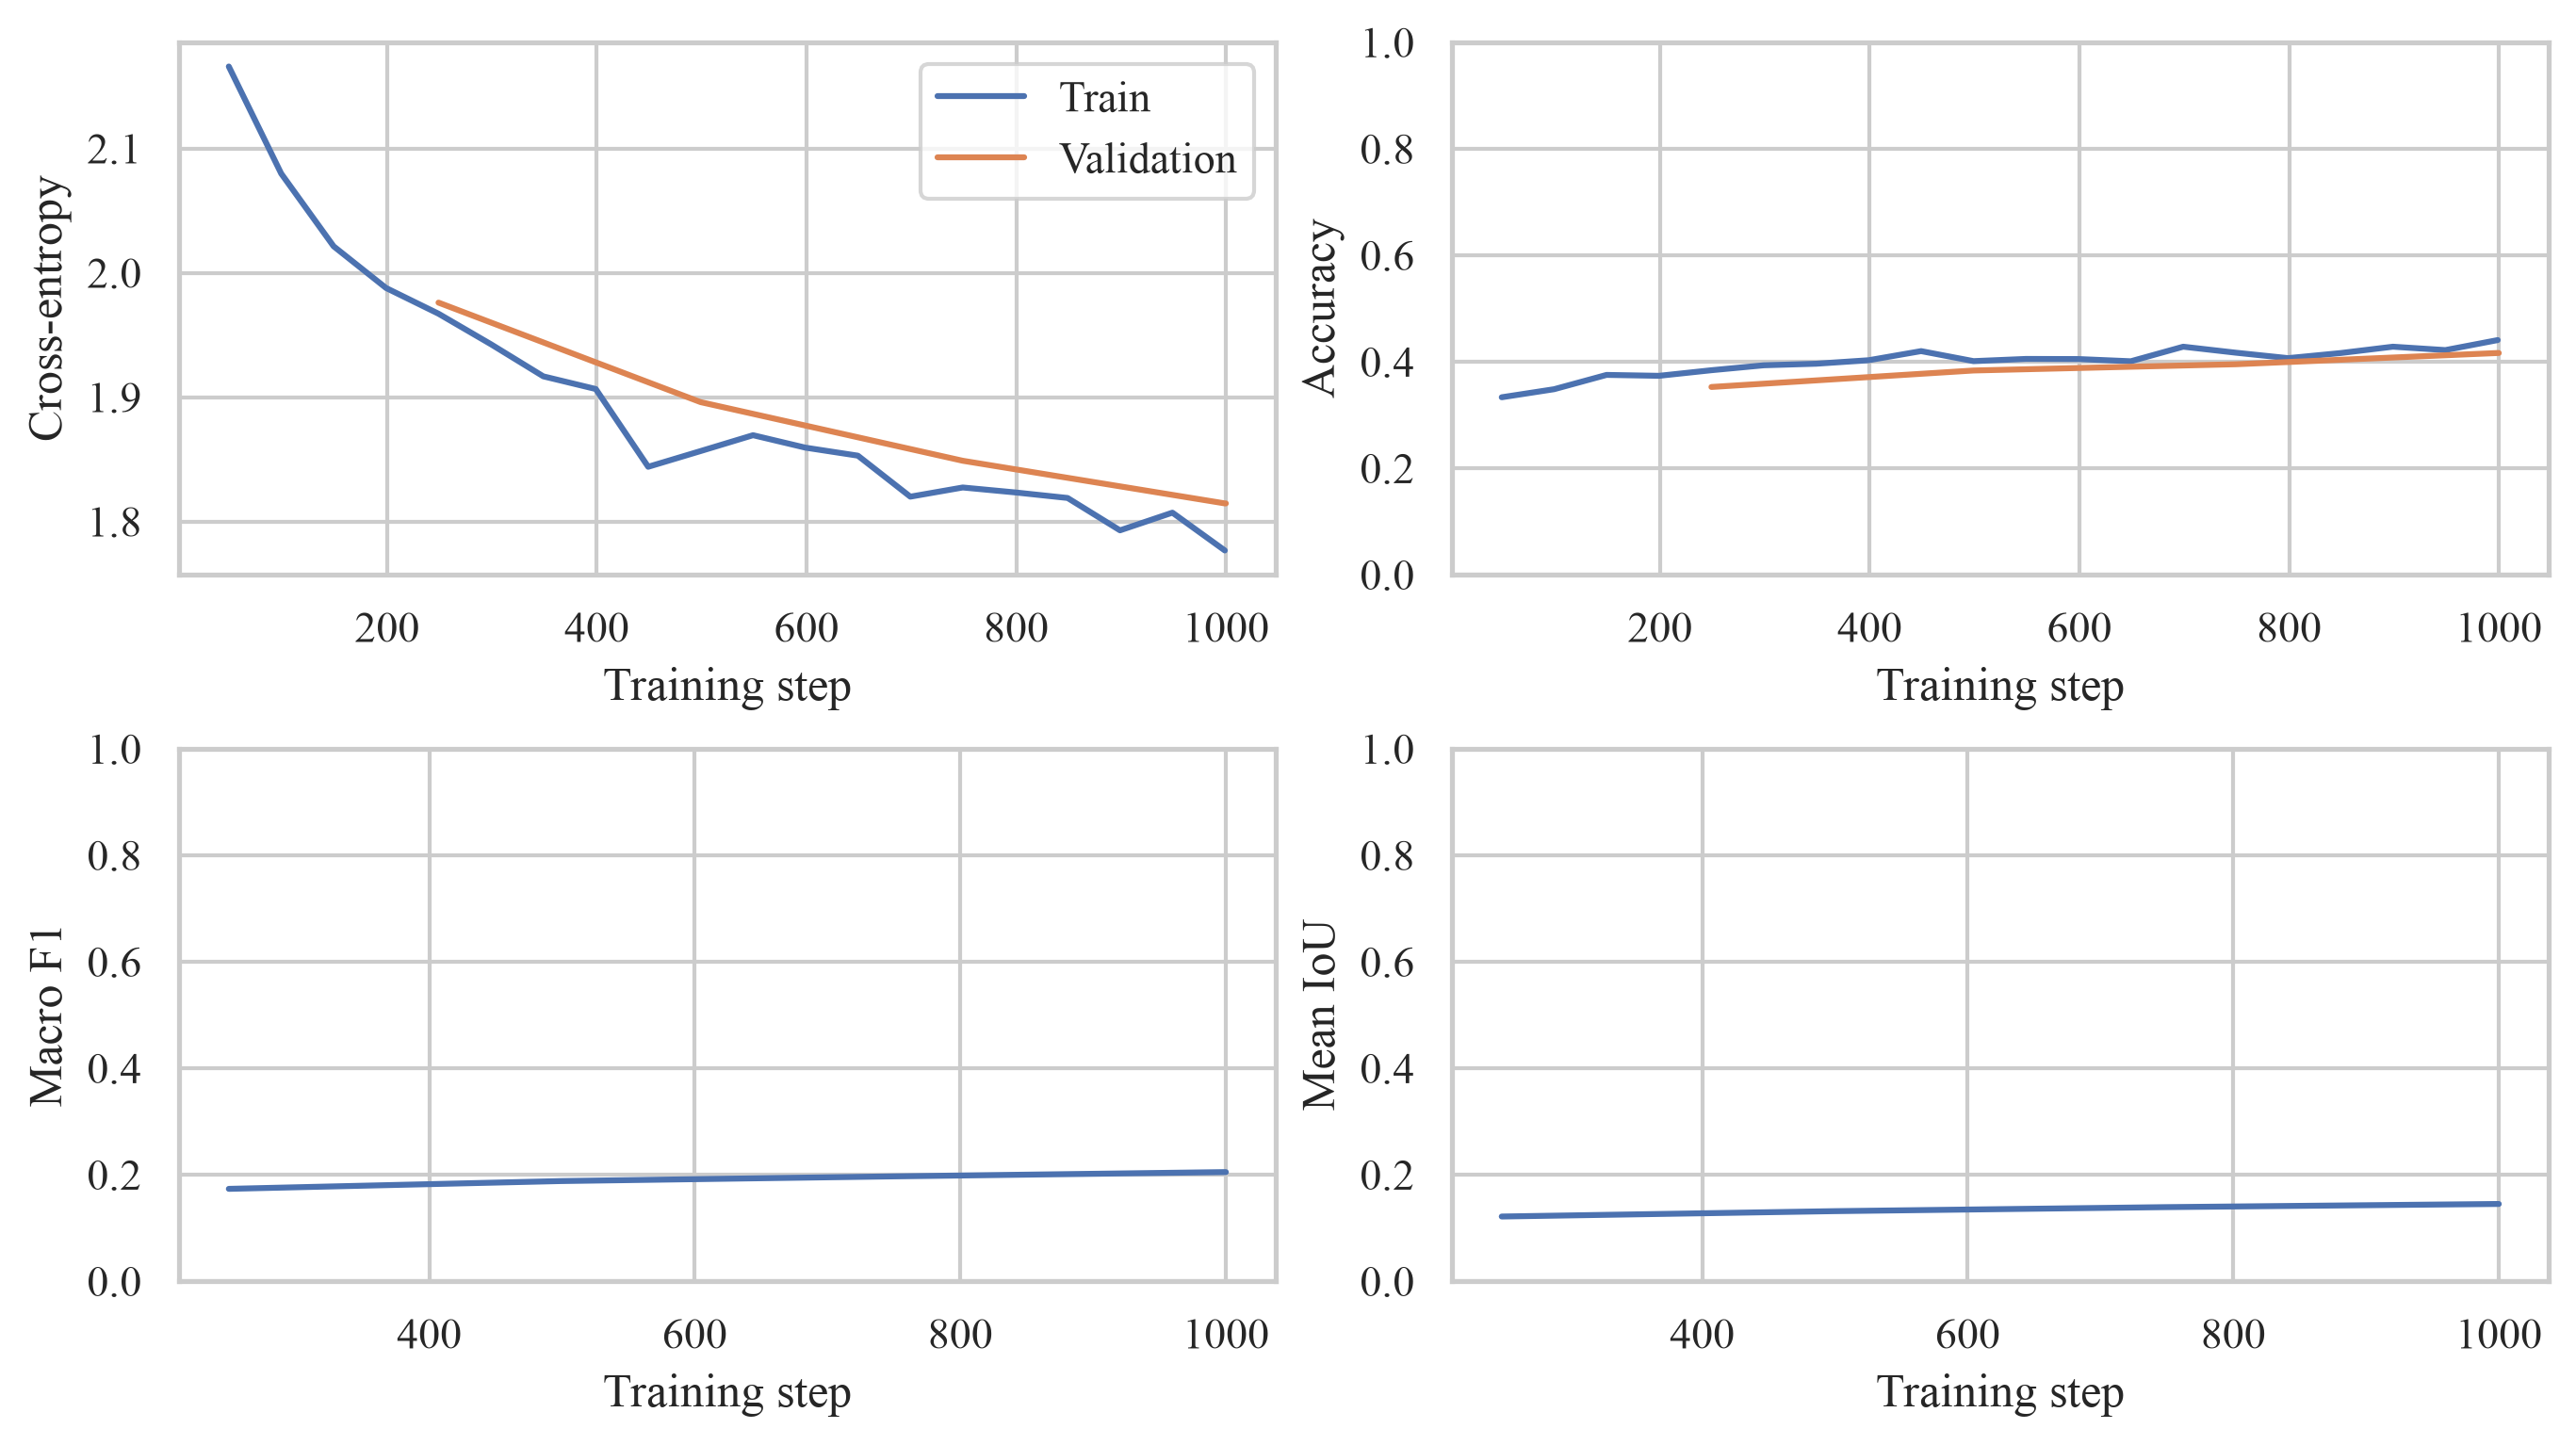

In [7]:
encoder = model[0].eval().requires_grad_(False)
linear_head = nn.Linear(cfg.hidden_dim, num_classes).to(device)
probe = nn.Sequential(encoder, linear_head)
probe_history = fit(probe, cfg.probe_steps, "linear_head")
plot_metrics(probe_history, cfg.output / "linear_head_metrics.png")


@torch.inference_mode()
def predict(network, features):
    return torch.cat(
        [
            network(part.to(device, copy=True)).cpu()
            for part in features.split(cfg.batch_size)
        ]
    )


torch.save(
    {
        "model": model.state_dict(),
        "linear_head": linear_head.state_dict(),
        "architecture": "hourglass",
        "input_dim": cfg.input_dim,
        "hidden_dim": cfg.hidden_dim,
        "output_dim": cfg.output_dim,
        "num_classes": num_classes,
        "class_codes": class_codes.tolist(),
    },
    cfg.output / "model.pt",
)

## Export ONNX

Save only the embedding encoder, with weights embedded in one file. `coords` is float32 `[batch, 2]` longitude/latitude in degrees. Optional `time` is float64 `[batch, 1]` UTC Unix seconds; omit it or pass `None` when empty. This model ignores time. The batch dimension is dynamic.

In [8]:
import copy

import onnx

program = torch.onnx.export(
    copy.deepcopy(model[0]).cpu().eval(),
    (torch.zeros(2, 2),),
    input_names=["coords"],
    output_names=["embeddings"],
    dynamic_shapes=({0: torch.export.Dim("batch", min=1)},),
    dynamo=True,
    external_data=False,
)
assert program is not None
onnx_model = program.model_proto
# Add optional time after export so the unused input is retained.
time_type = onnx.helper.make_tensor_type_proto(onnx.TensorProto.DOUBLE, ["batch", 1])
optional_time = onnx.helper.make_optional_type_proto(time_type)
onnx_model.graph.input.append(onnx.helper.make_value_info("time", optional_time))
onnx.save_model(onnx_model, cfg.output / "model.onnx", save_as_external_data=False)

W1105 08:57:31.833000 24276 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::nms


W1105 08:57:31.834000 24276 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align


W1105 08:57:31.834000 24276 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool


W1105 08:57:31.834000 24276 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


## PCA RGB

Fit PCA on sampled bottleneck embeddings and map three components to RGB, stretched to their 2nd–98th percentiles. Compare with land cover and both classifiers.

PCA explained variance: [0.345 0.278 0.218]


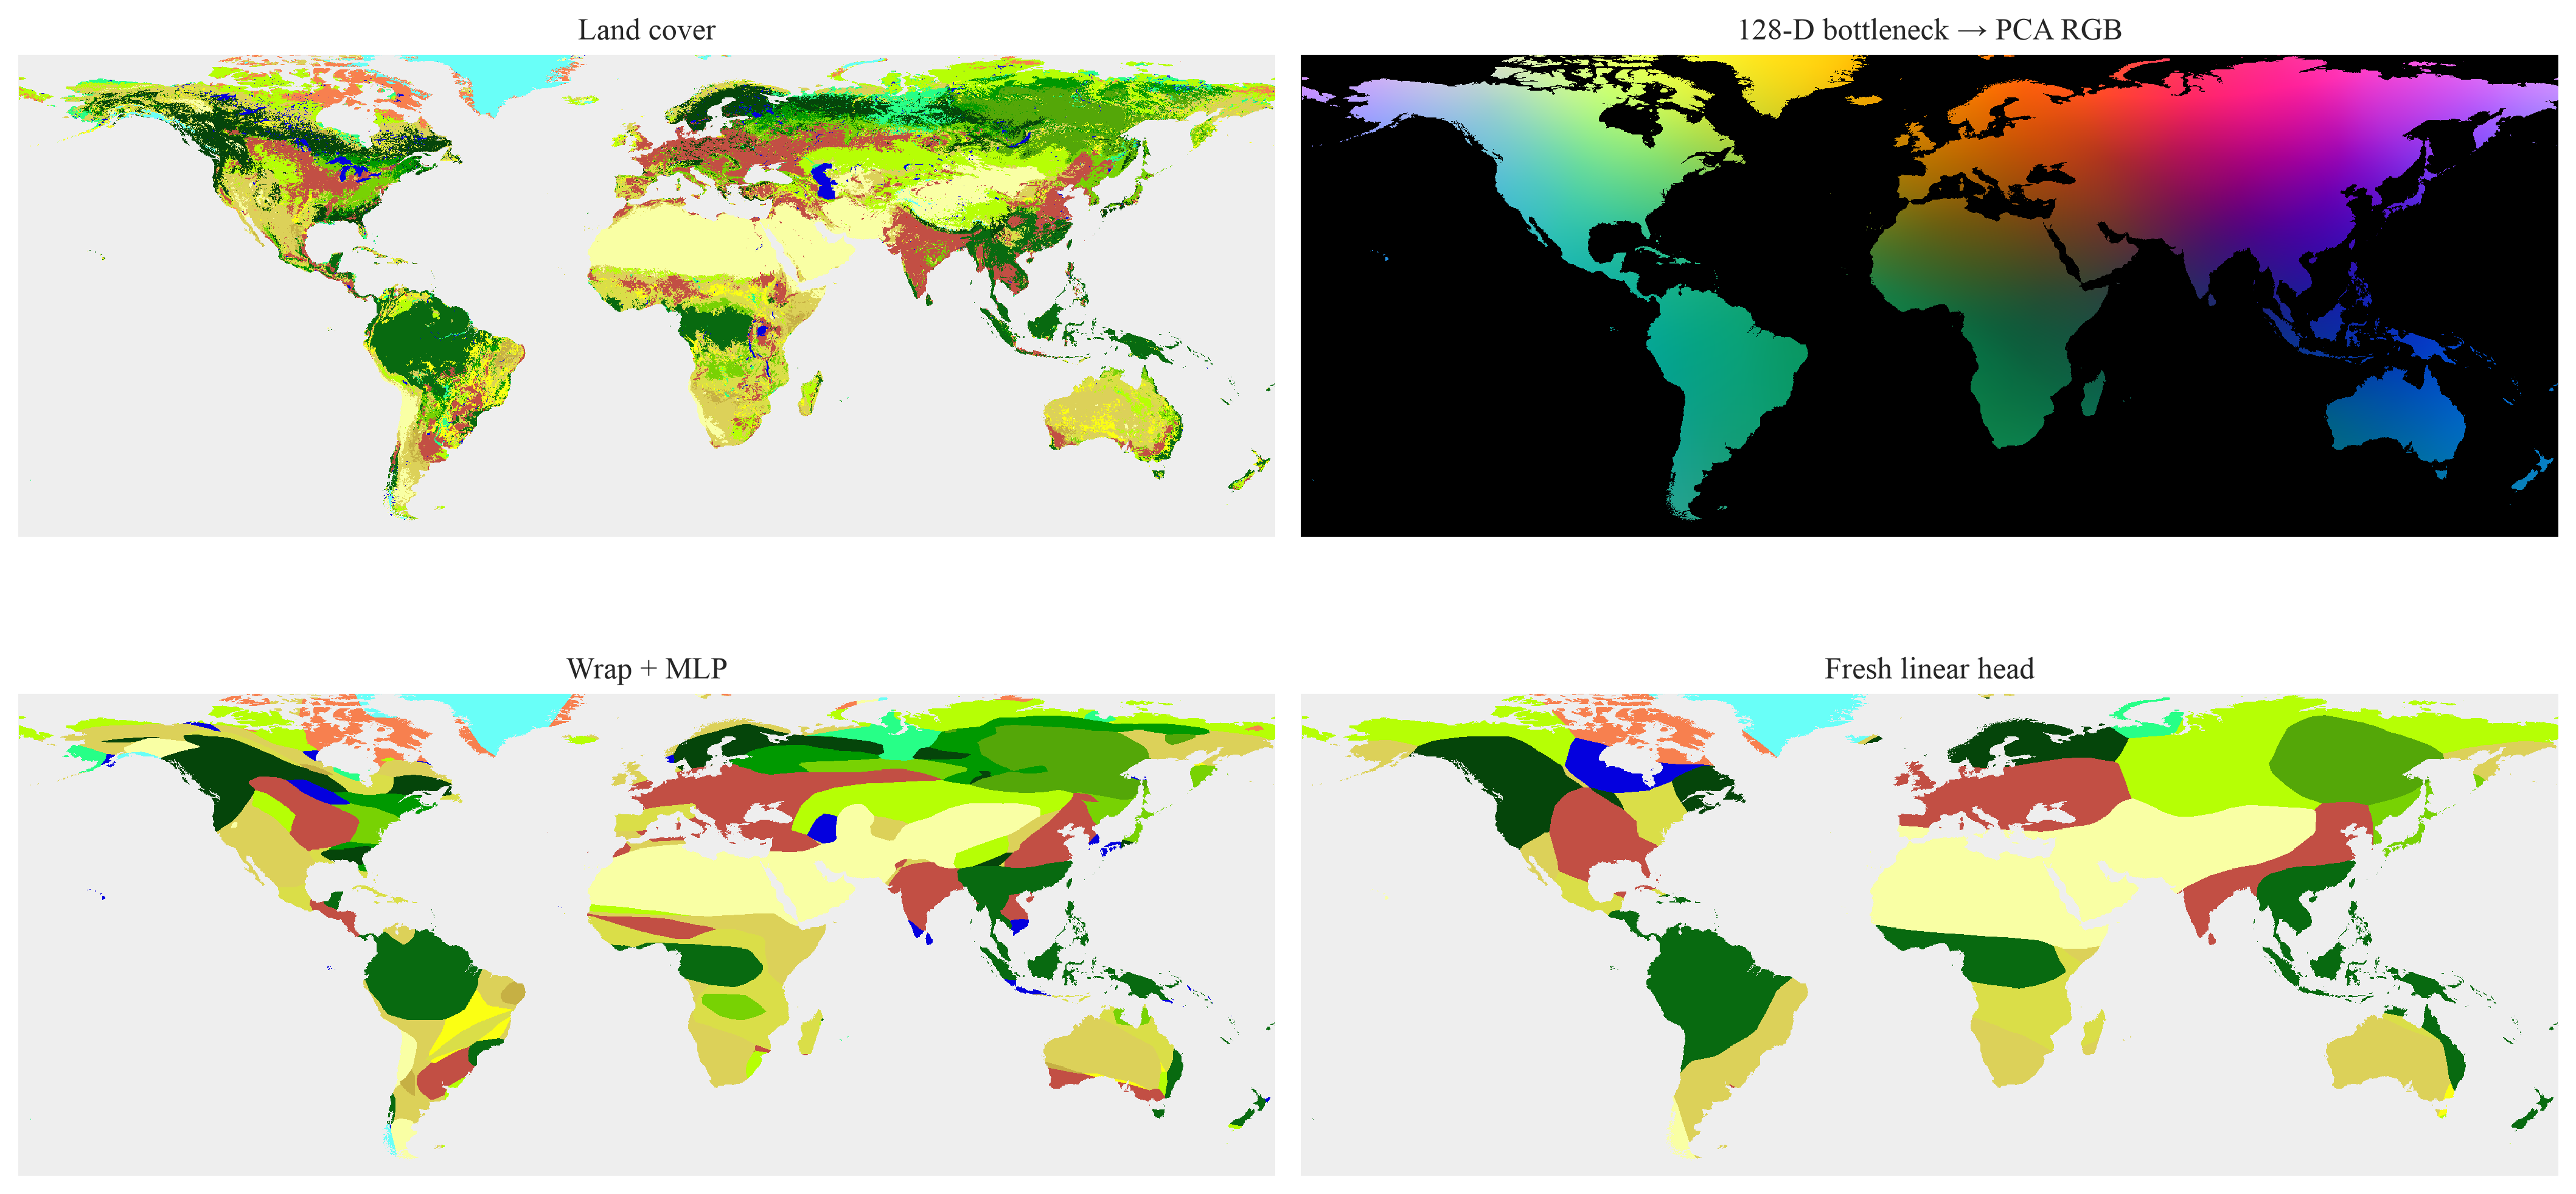

In [9]:
overview, coords = preview_grid(cfg.source, cfg.preview_height)
features = predict(encoder, torch.from_numpy(coords))
pca_features = predict(encoder, train_data.coords[:65536])
rgb = pca_rgb(pca_features.numpy(), features.numpy(), overview.shape, cfg.seed)
predictions = {
    name: predict(head, features).argmax(1).numpy().reshape(overview.shape)
    for name, head in [("Wrap + MLP", model[1:]), ("Fresh linear head", linear_head)]
}
plot_comparison(
    train_data.lookup[overview],
    predictions,
    rgb,
    colors,
    class_codes,
    cfg.hidden_dim,
    cfg.output / "global_comparison.png",
)

## Export rasters

Use [inference.ipynb](inference.ipynb) to export embedding COGs.

Dataset by Demuzere, He, Martilli, and Zonato (2023), [CC BY 4.0](https://doi.org/10.5281/zenodo.7670653).